# Reproducción de la Figura 2 de Bignardi et al. (2012) con el Método de Elementos de Contorno (BEM)

**Cilindro elástico infinitamente largo sometido a una presión normal armónica: BEM (8 y 32 elementos cuadráticos) vs. solución analítica de Kitahara (1984)**

> S. Bignardi, F. Fedele, A. Yezzi, G. Rix, G. Santarato (2012). *Geometric Seismic-Wave Inversion by the Boundary Element Method*. BSSA 102(2).
> M. Kitahara (1984). *Boundary Integral Equation Methods in Eigenvalue Problems of Elastodynamics and Thin Plates*. Elsevier.
> J. Domínguez (1993). *Boundary Elements in Dynamics*. CMP / Elsevier.

Este notebook es **autocontenido**: sólo usa `numpy`, `scipy` y `matplotlib`. Contiene

1. El planteamiento físico del problema y los parámetros del artículo.
2. La deducción de la **solución analítica** (Kitahara, 1984).
3. La teoría del **BEM directo en elastodinámica 2D** (identidad de Somigliana, solución fundamental, discretización con elementos cuadráticos isoparamétricos, integrales singulares).
4. La implementación completa del BEM, con pruebas de verificación de cada pieza.
5. La reproducción de la **Figura 2** y un breve estudio de convergencia.

En el artículo, esta figura es la *prueba de validación* del modelo directo (forward) que luego se usa dentro de la inversión geométrica: si el BEM no reproduce un caso con solución exacta, no tiene sentido usarlo para invertir datos.

## 0. Librerías y parámetros del problema

Parámetros tomados textualmente de Bignardi et al. (2012), sección *BEM-Based Forward Model*:

| Magnitud | Símbolo | Valor |
|---|---|---|
| Radio del cilindro | $R$ | 6 m (inserto de la Fig. 2) |
| Densidad | $\rho$ | 100 kg/m³ |
| Módulo de corte | $\mu$ | $10^6$ N/m² |
| Coeficiente de Poisson | $\nu$ | 0.25 |
| Razón de amortiguamiento | $\beta$ | 0.05 |
| Presión normal | $p$ | 100 N/m² |
| Rango de frecuencias | $\omega$ | $10 < \omega < 150$ rad/s |
| Primera frecuencia de resonancia | $\omega_1$ | 59.73 rad/s |

*Nota:* en el PDF la carga aparece como “$f_0 = 100^2$”, pero el desplazamiento casi estático de la figura ($\approx 1.5\times10^{-4}$ m) sólo es compatible con $p = 100$ N/m² (lo comprobamos abajo con el límite estático).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch, Arc
from scipy.special import kv, kvp, jv
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

R    = 6.0      # radio [m]
RHO  = 100.0    # densidad [kg/m^3]
MU   = 1.0e6    # módulo de corte [N/m^2]
NU   = 0.25     # coeficiente de Poisson
BETA = 0.05     # razón de amortiguamiento histerético
P    = 100.0    # presión normal [N/m^2]

## 1. Planteamiento físico

Consideramos un cilindro sólido, homogéneo, isótropo y **infinitamente largo** en la dirección $z$. Una presión uniforme $p\,e^{i\omega t}$ actúa sobre toda su superficie lateral. Como ni la geometría ni la carga dependen de $z$, el problema es de **deformación plana** y basta estudiar la sección transversal: un círculo $\Omega$ de radio $R$ con contorno $\Gamma$.

Por simetría axial el único desplazamiento es el **radial**, $u_r(r)$; la Figura 2 grafica $|u_r(R)|$ en función de $\omega/\omega_1$.

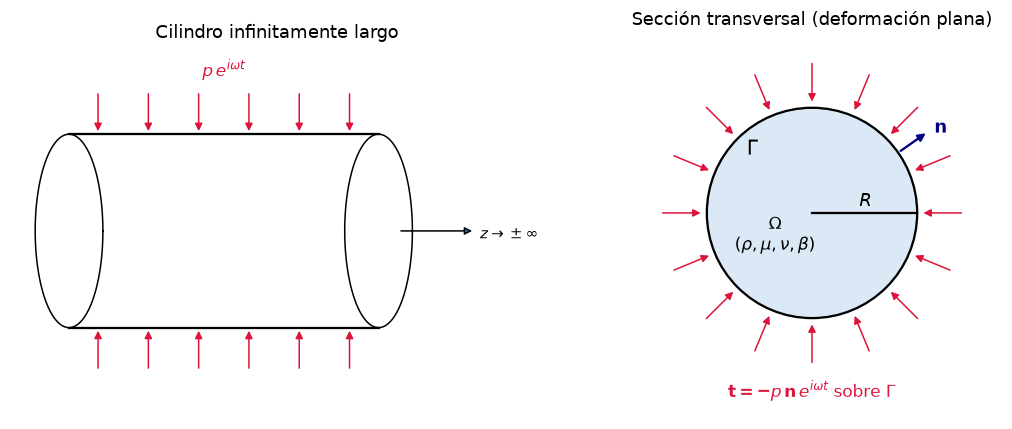

In [2]:
def esquema_problema(ax):
    ax.add_patch(Circle((0, 0), 1, fc="#dbe9f6", ec="k", lw=1.5))
    for th in np.linspace(0, 2*np.pi, 16, endpoint=False):
        c, s = np.cos(th), np.sin(th)
        ax.add_patch(FancyArrowPatch((1.45*c, 1.45*s), (1.03*c, 1.03*s),
                                     arrowstyle="-|>", mutation_scale=10, color="crimson"))
    # normal exterior
    th = np.deg2rad(35); c, s = np.cos(th), np.sin(th)
    ax.annotate("", xy=(1.0*c+0.35*c, 1.0*s+0.35*s), xytext=(c, s),
                arrowprops=dict(arrowstyle="-|>", color="navy", lw=1.5))
    ax.text(1.42*c, 1.32*s, r"$\mathbf{n}$", color="navy", fontsize=12)
    ax.plot([0, 1], [0, 0], "k-"); ax.text(0.45, 0.06, r"$R$", fontsize=12)
    ax.text(-0.35, -0.35, r"$\Omega$" "\n" r"$(\rho,\mu,\nu,\beta)$", fontsize=11, ha="center")
    ax.text(-0.62, 0.55, r"$\Gamma$", fontsize=13)
    ax.text(0.0, -1.75, r"$\mathbf{t} = -p\,\mathbf{n}\,e^{i\omega t}$ sobre $\Gamma$", color="crimson",
            ha="center", fontsize=11)
    ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.95, 1.7); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Sección transversal (deformación plana)")

def esquema_3d(ax):
    # cilindro largo en perspectiva simple
    for x0 in (0, 3.2):
        e = matplotlib_ellipse(x0)
        ax.plot(*e, "k-", lw=1)
    ax.plot([0, 3.2], [1, 1], "k-"); ax.plot([0, 3.2], [-1, -1], "k-")
    ax.annotate("", xy=(4.2, 0), xytext=(3.4, 0), arrowprops=dict(arrowstyle="-|>"))
    ax.text(4.25, -0.08, r"$z\to\pm\infty$")
    for x0 in np.linspace(0.3, 2.9, 6):
        ax.annotate("", xy=(x0, 1.0), xytext=(x0, 1.45), arrowprops=dict(arrowstyle="-|>", color="crimson"))
        ax.annotate("", xy=(x0, -1.0), xytext=(x0, -1.45), arrowprops=dict(arrowstyle="-|>", color="crimson"))
    ax.text(1.6, 1.6, r"$p\,e^{i\omega t}$", color="crimson", ha="center", fontsize=11)
    ax.set_xlim(-0.6, 4.9); ax.set_ylim(-1.8, 1.9); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Cilindro infinitamente largo")

def matplotlib_ellipse(x0):
    t = np.linspace(0, 2*np.pi, 100)
    return x0 + 0.35*np.cos(t), np.sin(t)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
esquema_3d(axs[0]); esquema_problema(axs[1])
plt.tight_layout(); plt.show()

### 1.1 Ecuaciones de gobierno en el dominio de la frecuencia

Con dependencia temporal armónica $\mathbf u(\mathbf x,t)=\mathbf u(\mathbf x)\,e^{i\omega t}$, la ecuación de Navier sin fuerzas de volumen queda

$$
\mu\,\nabla^2\mathbf u + (\lambda+\mu)\,\nabla(\nabla\!\cdot\mathbf u) + \rho\,\omega^2\,\mathbf u = \mathbf 0 \quad \text{en } \Omega,
$$

con tracciones en el contorno $t_j = \sigma_{jk}n_k$, $\;\sigma_{jk} = \lambda\,\delta_{jk}\,u_{m,m} + \mu\,(u_{j,k}+u_{k,j})$.

Hay dos velocidades de onda: $c_s=\sqrt{\mu/\rho}$ (corte, S) y $c_p=\sqrt{(\lambda+2\mu)/\rho}$ (compresión, P).

### 1.2 Amortiguamiento: principio de correspondencia

El amortiguamiento histerético (independiente de la frecuencia) se introduce con el **principio de correspondencia elástico–viscoelástico**: se reemplazan los módulos reales por complejos

$$
\mu^* = \mu\,(1+2i\beta), \qquad \lambda^* = \lambda\,(1+2i\beta),
$$

de modo que $\nu$ permanece real y las velocidades $c_s^*, c_p^*$ se vuelven complejas. Todas las fórmulas que siguen son idénticas al caso elástico, sólo que con $\mu^*,\lambda^*$. (Con $\beta=0$ la respuesta en resonancia sería infinita; con $\beta=0.05$ el pico es finito, $\approx 11.8\times10^{-4}$ m como en la figura.)

In [3]:
def material(rho=RHO, mu=MU, nu=NU, beta=BETA):
    mu_c  = mu*(1 + 2j*beta)
    lam_c = 2*mu_c*nu/(1 - 2*nu)
    return dict(rho=rho, mu=mu_c, lam=lam_c, nu=nu,
                cs=np.sqrt(mu_c/rho), cp=np.sqrt((lam_c + 2*mu_c)/rho))

mat = material()
print(f"lambda* = {mat['lam']:.3e} N/m^2,  mu* = {mat['mu']:.3e} N/m^2")
print(f"c_s* = {mat['cs']:.3f} m/s,  c_p* = {mat['cp']:.3f} m/s")

lambda* = 1.000e+06+1.000e+05j N/m^2,  mu* = 1.000e+06+1.000e+05j N/m^2
c_s* = 100.125+4.994j m/s,  c_p* = 173.421+8.649j m/s


## 2. Solución analítica (Kitahara, 1984)

### 2.1 Deducción

Por simetría $\mathbf u = u_r(r)\,\mathbf e_r$ y $\nabla\times\mathbf u=\mathbf 0$: el campo es **puramente irrotacional**, sólo hay ondas P. Navier se reduce a la ecuación de Bessel de orden 1:

$$
u_r'' + \frac{1}{r}u_r' - \frac{1}{r^2}u_r + k_p^2\,u_r = 0, \qquad k_p = \frac{\omega}{c_p}.
$$

La solución regular en $r=0$ es $u_r(r) = A\,J_1(k_p r)$ ($Y_1$ se descarta porque diverge en el eje).

La tensión radial es $\sigma_{rr} = (\lambda+2\mu)\,u_r' + \lambda\,u_r/r$. Usando $J_1'(x)=J_0(x)-J_1(x)/x$:

$$
\sigma_{rr}(r) = A\left[(\lambda+2\mu)\,k_p\,J_0(k_p r) - \frac{2\mu}{r}\,J_1(k_p r)\right].
$$

La condición de contorno de presión, $\sigma_{rr}(R) = -p$, fija $A$ y da el desplazamiento radial en la superficie:

$$
\boxed{\,u_r(R,\omega) = \frac{-\,p\,R\;J_1(k_pR)}{(\lambda+2\mu)\,k_pR\,J_0(k_pR) - 2\mu\,J_1(k_pR)}\,}
$$

### 2.2 Dos comprobaciones

* **Límite estático** ($\omega\to0$, $J_1(x)\approx x/2$, $J_0\approx1$): $u_r(R) \to -\dfrac{pR}{2(\lambda+\mu)}$, que es la solución clásica de Lamé en deformación plana. Con los datos: $100\cdot 6/(2\cdot 2\times10^6)=1.5\times10^{-4}$ m, justo el valor de la izquierda de la Fig. 2. ✔
* **Resonancias** (sin amortiguamiento): el denominador se anula,

$$
(\lambda+2\mu)\,x\,J_0(x) = 2\mu\,J_1(x), \quad x=k_pR \;\;\xrightarrow{\;\nu=0.25\;}\;\; 3\,x\,J_0(x) = 2\,J_1(x).
$$

La primera raíz es el **modo de respiración** (*breathing mode*) del cilindro, $\omega_1 = x_1\,c_p/R$.

In [4]:
def u_r_analitico(omega, m=mat, R=R, p=P):
    # Desplazamiento radial en r=R (Kitahara 1984). Acepta omega escalar o vector.
    x = omega/m["cp"]*R
    L, M = m["lam"], m["mu"]
    return -p*R*jv(1, x)/((L + 2*M)*x*jv(0, x) - 2*M*jv(1, x))

# primera frecuencia de resonancia del sistema SIN amortiguamiento
m0 = material(beta=0.0)
x1 = brentq(lambda x: (m0["lam"] + 2*m0["mu"]).real*x*jv(0, x) - 2*m0["mu"].real*jv(1, x), 1.0, 3.0)
OMEGA1 = x1*m0["cp"].real/R
print(f"x1 = k_p R = {x1:.5f}  ->  omega_1 = {OMEGA1:.2f} rad/s   (artículo: 59.73 rad/s)")
print(f"límite estático  pR/(2(lam+mu)) = {P*R/(2*(m0['lam'].real + m0['mu'].real)):.3e} m")
print(f"|u_r(omega=10)|  = {abs(u_r_analitico(10.0)):.3e} m")

x1 = k_p R = 2.06940  ->  omega_1 = 59.74 rad/s   (artículo: 59.73 rad/s)
límite estático  pR/(2(lam+mu)) = 1.500e-04 m
|u_r(omega=10)|  = 1.527e-04 m


## 3. El método de elementos de contorno (BEM) directo

### 3.1 Idea central

En lugar de discretizar todo el dominio $\Omega$ (como FEM), el BEM reformula la EDP como una **ecuación integral sobre el contorno** $\Gamma$. Sólo se discretiza la curva: el problema 2D se convierte en un problema 1D. Las incógnitas son los desplazamientos $\mathbf u$ y tracciones $\mathbf t$ en $\Gamma$.

```
         FEM                                  BEM
   ┌───────────────┐                   ┌───────────────┐
   │▦▦▦▦▦▦▦▦▦▦▦▦▦▦▦│                   │●─●─●─●─●─●─●─●│
   │▦▦▦▦ malla ▦▦▦▦│                   │●             ●│
   │▦▦▦ de área ▦▦▦│        vs.        │●   (vacío)   ●│
   │▦▦▦▦▦▦▦▦▦▦▦▦▦▦▦│                   │●             ●│
   └───────────────┘                   │●─●─●─●─●─●─●─●│
   incógnitas ~ N²                      incógnitas ~ N
```

### 3.2 Teorema de reciprocidad y solución fundamental

La herramienta es el **teorema de reciprocidad de Betti** (Maxwell–Betti) aplicado entre

* el estado real $(\mathbf u,\mathbf t)$ que buscamos, y
* un estado auxiliar: la respuesta de un **espacio infinito** a una carga puntual unitaria armónica aplicada en $\boldsymbol\xi$ en la dirección $i$. Su desplazamiento en $\mathbf x$ en la dirección $j$ es la **solución fundamental** $U_{ij}(\mathbf x,\boldsymbol\xi,\omega)$, y su tracción $T_{ij}$.

Para elastodinámica 2D (Domínguez, 1993):

$$
U_{ij} = \frac{1}{2\pi\mu}\Big[\psi\,\delta_{ij} - \chi\,r_{,i}\,r_{,j}\Big],
$$

$$
\psi = K_0(z_s) + \frac{1}{z_s}\Big[K_1(z_s) - \frac{c_s}{c_p}K_1(z_p)\Big],\qquad
\chi = K_2(z_s) - \Big(\frac{c_s}{c_p}\Big)^2 K_2(z_p),\qquad z_{s,p}=\frac{i\omega r}{c_{s,p}},
$$

donde $r=|\mathbf x-\boldsymbol\xi|$, $r_{,i}=(x_i-\xi_i)/r$ y $K_n$ son funciones de Bessel modificadas de segunda especie. Derivando $U_{ij}$ y aplicando la ley de Hooke se obtiene la tracción ($\partial r/\partial n = r_{,k}n_k$):

$$
T_{ij} = \frac{1}{2\pi}\Big[\Big(\frac{d\psi}{dr}-\frac{\chi}{r}\Big)\Big(\delta_{ij}\frac{\partial r}{\partial n}+r_{,j}n_i\Big)
-\frac{2\chi}{r}\Big(n_j r_{,i}-2r_{,i}r_{,j}\frac{\partial r}{\partial n}\Big)
-2\frac{d\chi}{dr}r_{,i}r_{,j}\frac{\partial r}{\partial n}
+\Big(\frac{c_p^2}{c_s^2}-2\Big)\Big(\frac{d\psi}{dr}-\frac{d\chi}{dr}-\frac{\chi}{r}\Big)r_{,i}n_j\Big].
$$

**Comportamiento cerca de la fuente** ($r\to0$): $U_{ij}\sim\ln(1/r)$ (*débilmente singular*) y $T_{ij}\sim 1/r$ (*fuertemente singular*). Además, $T_{ij}$ tiene la **misma singularidad** que la solución estática de Kelvin, $T^{s}_{ij}$:

$$
T^{s}_{ij} = \frac{-1}{4\pi(1-\nu)\,r}\Big[\frac{\partial r}{\partial n}\big((1-2\nu)\delta_{ij}+2r_{,i}r_{,j}\big) - (1-2\nu)\big(r_{,i}n_j - r_{,j}n_i\big)\Big].
$$

Esto será clave para tratar las integrales singulares (sección 3.5).

### 3.3 Ecuación integral de contorno (identidad de Somigliana)

Aplicando reciprocidad y llevando el punto fuente $\boldsymbol\xi$ al contorno:

$$
c_{ij}(\boldsymbol\xi)\,u_j(\boldsymbol\xi) + \mathrm{VP}\!\!\int_\Gamma T_{ij}(\mathbf x,\boldsymbol\xi)\,u_j(\mathbf x)\,d\Gamma
= \int_\Gamma U_{ij}(\mathbf x,\boldsymbol\xi)\,t_j(\mathbf x)\,d\Gamma ,\qquad \boldsymbol\xi\in\Gamma,
$$

que es la ec. (1) de Bignardi et al. ($c_{ij}=\tfrac12\delta_{ij}$ en contornos suaves; “VP” = valor principal de Cauchy).

### 3.4 Discretización: elementos cuadráticos isoparamétricos

Como en el artículo (ec. 3), $\Gamma$ se divide en $N_e$ elementos de **3 nodos**. Cada elemento se mapea desde el intervalo de referencia $\eta\in[-1,1]$ con funciones de forma cuadráticas, y la **misma** interpolación se usa para la geometría, $\mathbf u$ y $\mathbf t$ (*isoparamétrico*):

$$
\mathbf x(\eta)=\sum_{n=1}^{3}P_n(\eta)\,\mathbf x_n,\quad
\mathbf u(\eta)=\sum_{n=1}^{3}P_n(\eta)\,\mathbf u_n,\quad
\mathbf t(\eta)=\sum_{n=1}^{3}P_n(\eta)\,\mathbf t_n,
$$

$$
P_1=\tfrac12\eta(\eta-1),\qquad P_2=1-\eta^2,\qquad P_3=\tfrac12\eta(\eta+1),
\qquad d\Gamma = J(\eta)\,d\eta,\;\; J=\Big|\frac{d\mathbf x}{d\eta}\Big|.
$$

Los nodos extremos se comparten entre elementos vecinos (continuidad), así que $N_e$ elementos dan $2N_e$ nodos: **8 elementos → 16 nodos**, **32 elementos → 64 nodos** (los puntos de los insertos de la Fig. 2).

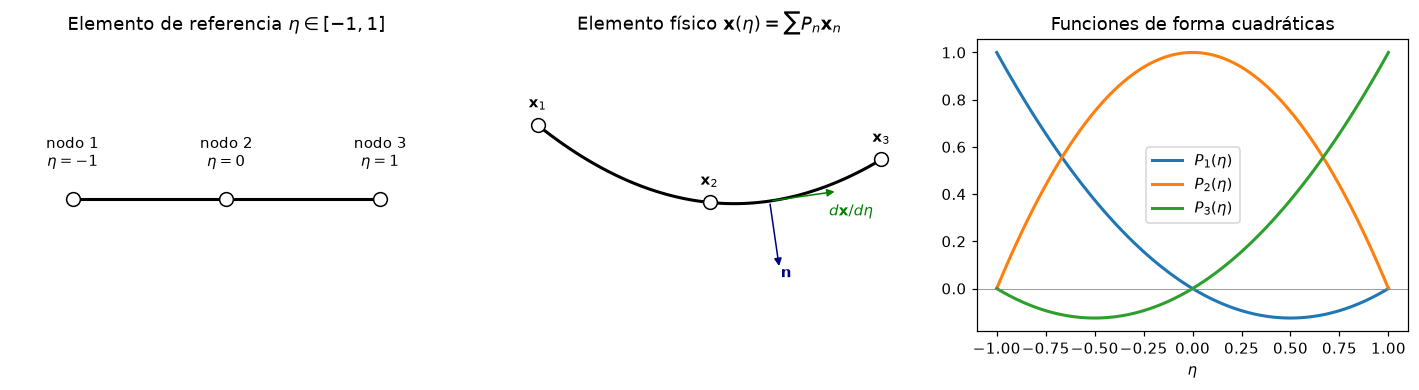

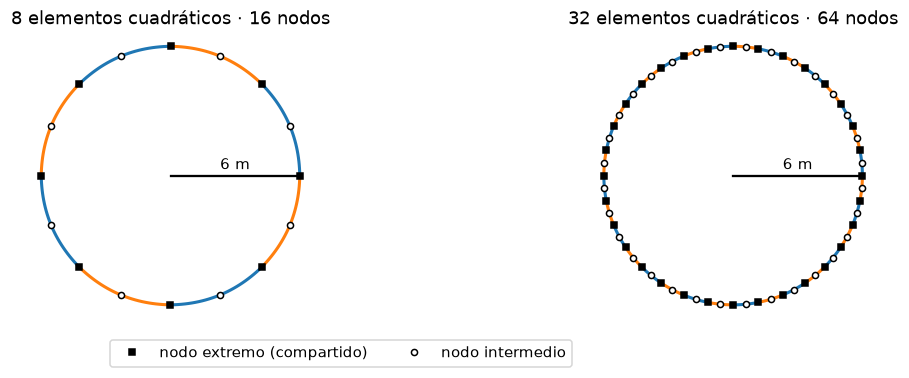

In [5]:
def shape(eta):
    eta = np.asarray(eta, float)
    return np.stack([0.5*eta*(eta - 1), 1 - eta**2, 0.5*eta*(eta + 1)], -1)

def dshape(eta):
    eta = np.asarray(eta, float)
    return np.stack([eta - 0.5, -2*eta, eta + 0.5], -1)

def malla_circulo(R, ne):
    # nodos en sentido antihorario; conectividad (elemento -> 3 nodos globales)
    nn = 2*ne
    th = np.linspace(0, 2*np.pi, nn, endpoint=False)
    nodes = R*np.stack([np.cos(th), np.sin(th)], -1)
    conn = np.array([[2*e, 2*e + 1, (2*e + 2) % nn] for e in range(ne)])
    return nodes, conn

# --- Esquema: elemento de referencia -> elemento curvo, y funciones de forma ---
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axs[0]
ax.plot([-1, 1], [0, 0], "k-", lw=2)
for e, lab in zip([-1, 0, 1], ["1", "2", "3"]):
    ax.plot(e, 0, "o", ms=9, mfc="w", mec="k"); ax.text(e, 0.12, f"nodo {lab}\n$\\eta={e}$", ha="center")
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-0.5, 0.6); ax.axis("off"); ax.set_title(r"Elemento de referencia $\eta\in[-1,1]$")

ax = axs[1]
xn = np.array([[0.0, 0.0], [1.0, -0.45], [2.0, -0.2]])   # tramo inferior de un contorno antihorario
eta = np.linspace(-1, 1, 100); X = shape(eta) @ xn
ax.plot(X[:, 0], X[:, 1], "k-", lw=2)
for k, q in enumerate(xn):
    ax.plot(*q, "o", ms=9, mfc="w", mec="k"); ax.text(q[0], q[1] + 0.1, rf"$\mathbf{{x}}_{k+1}$", ha="center")
e0 = 0.35; x0 = shape(e0) @ xn; dx = dshape(e0) @ xn; nvec = np.array([dx[1], -dx[0]])/np.linalg.norm(dx)
ax.annotate("", xy=x0 + 0.4*nvec, xytext=x0, arrowprops=dict(arrowstyle="-|>", color="navy"))
ax.text(*(x0 + 0.45*nvec), r"$\mathbf{n}$", color="navy")
ax.annotate("", xy=x0 + 0.4*dx/np.linalg.norm(dx), xytext=x0, arrowprops=dict(arrowstyle="-|>", color="green"))
ax.text(*(x0 + 0.45*dx/np.linalg.norm(dx) + [-0.1, -0.15]), r"$d\mathbf{x}/d\eta$", color="green")
ax.set_ylim(-1.2, 0.5); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(r"Elemento físico $\mathbf{x}(\eta)=\sum P_n\mathbf{x}_n$")

ax = axs[2]
Pn = shape(eta)
for k in range(3): ax.plot(eta, Pn[:, k], lw=2, label=f"$P_{k+1}(\\eta)$")
ax.axhline(0, color="gray", lw=0.5); ax.legend(); ax.set_xlabel(r"$\eta$"); ax.set_title("Funciones de forma cuadráticas")
plt.tight_layout(); plt.show()

# --- Esquema: las dos mallas de la Fig. 2 ---
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
for ax, ne in zip(axs, (8, 32)):
    nodes, conn = malla_circulo(R, ne)
    eta = np.linspace(-1, 1, 30)
    for k, cn in enumerate(conn):
        X = shape(eta) @ nodes[cn]
        ax.plot(X[:, 0], X[:, 1], "-", color=plt.cm.tab10(k % 2), lw=2)
    ax.plot(nodes[0::2, 0], nodes[0::2, 1], "ks", ms=4, label="nodo extremo (compartido)")
    ax.plot(nodes[1::2, 0], nodes[1::2, 1], "o", mfc="w", mec="k", ms=4, label="nodo intermedio")
    ax.plot([0, R], [0, 0], "k-"); ax.text(R/2, 0.3, "6 m", ha="center")
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(f"{ne} elementos cuadráticos · {2*ne} nodos")
axs[0].legend(loc="lower center", bbox_to_anchor=(1.1, -0.2), ncol=2)
plt.tight_layout(); plt.show()

### 3.5 Colocación y sistema lineal $\mathbf H\mathbf u = \mathbf G\mathbf t$

Se impone la ecuación integral en cada nodo $\boldsymbol\xi_i$ (**colocación nodal**). Sustituyendo la interpolación:

$$
\sum_{\text{elem. } e}\;\sum_{n=1}^{3}\Big[\underbrace{\int_{-1}^{1}T(\mathbf x(\eta),\boldsymbol\xi_i)\,P_n(\eta)\,J\,d\eta}_{\to\ \mathbf H_{i,g(e,n)}}\Big]\mathbf u_{g(e,n)}
=\sum_{e}\sum_{n}\Big[\underbrace{\int_{-1}^{1}U(\mathbf x(\eta),\boldsymbol\xi_i)\,P_n(\eta)\,J\,d\eta}_{\to\ \mathbf G_{i,g(e,n)}}\Big]\mathbf t_{g(e,n)}
$$

($g(e,n)$ = número global del nodo $n$ del elemento $e$; cada bloque es $2\times2$). El término libre $c_{ij}$ va en los bloques diagonales $\mathbf H_{ii}$. Resultado: un sistema denso de tamaño $2N_\text{nodos}$ (ec. 4 del artículo).

En este problema **todas las tracciones son conocidas**, $\mathbf t = -p\,\mathbf n$, así que sólo se resuelve $\mathbf H\mathbf u = \mathbf G\mathbf t$ para $\mathbf u$, y se calcula $u_r=\mathbf u\cdot\mathbf n$.

### 3.6 Integrales singulares (el punto delicado)

Cuando el punto de colocación $\boldsymbol\xi_i$ pertenece al elemento que se integra, $r\to0$ dentro de la integral:

| Integral | Singularidad | Tratamiento |
|---|---|---|
| $\int U\,P_n\,J\,d\eta$ | $\ln(1/r)$ — integrable | Partir el elemento en $\eta_i$ y usar Gauss con cambio de variable $\eta=\eta_i\pm(\ldots)t^2$, que agrupa puntos cerca de la singularidad y cancela el $\ln$ |
| $\int T\,P_n\,J\,d\eta$, bloque $i\ne g$ | $P_n(\eta_i)=0$ ⇒ acotada | Mismo esquema |
| $\mathbf H_{ii}$ (término libre + VP) | $1/r$ — fuertemente singular | **Movimiento de sólido rígido** sobre la parte estática |

**Truco del sólido rígido.** Separamos $T = T^s + (T-T^s)$. La diferencia $T-T^s$ es regular (la singularidad dinámica es idéntica a la estática). Para la parte estática: una traslación rígida $\mathbf u=\text{cte}$, $\mathbf t=\mathbf 0$ es solución exacta del problema estático, así que $\sum_g \mathbf H^s_{ig}=\mathbf 0$ y

$$
\mathbf H^s_{ii} = -\sum_{g\neq i}\mathbf H^s_{ig}.
$$

Así se obtiene $c_{ij}$ + VP **sin calcularlos explícitamente**. Además $\mathbf H^s$ no depende de $\omega$: se calcula **una sola vez**.

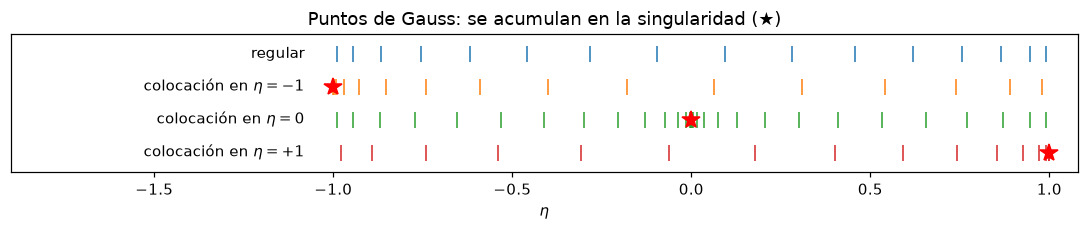

In [6]:
# Esquema de la cuadratura singular sobre un elemento con el punto de colocación en eta_s
GX, GW = np.polynomial.legendre.leggauss(16)

def puntos_cuadratura(eta_s=None):
    # Gauss-Legendre en [-1,1]; si eta_s se da, se parte ahí y se agrupan puntos con un mapeo cuadrático
    if eta_s is None:
        return GX.copy(), GW.copy()
    t, wt = (GX + 1)/2, GW/2
    pts, wts = [], []
    for a, b in [(-1.0, eta_s), (eta_s, 1.0)]:
        if b - a < 1e-12:
            continue
        if a == eta_s:      # singularidad en el extremo izquierdo del subintervalo
            s, ds = t**2, 2*t
        else:               # singularidad en el extremo derecho
            s, ds = 1 - (1 - t)**2, 2*(1 - t)
        pts.append(a + (b - a)*s); wts.append(wt*ds*(b - a))
    return np.concatenate(pts), np.concatenate(wts)

fig, ax = plt.subplots(figsize=(10, 2.2))
for y, (eta_s, lab) in enumerate([(None, "regular"), (-1.0, r"colocación en $\eta=-1$"),
                                   (0.0, r"colocación en $\eta=0$"), (1.0, r"colocación en $\eta=+1$")]):
    e, _ = puntos_cuadratura(eta_s)
    ax.plot(e, np.full_like(e, -y), "|", ms=10)
    if eta_s is not None: ax.plot(eta_s, -y, "r*", ms=12)
    ax.text(-1.08, -y, lab, ha="right", va="center")
ax.set_xlim(-1.9, 1.08); ax.set_ylim(-3.6, 0.6); ax.set_yticks([]); ax.set_xlabel(r"$\eta$")
ax.set_title("Puntos de Gauss: se acumulan en la singularidad (★)"); plt.tight_layout(); plt.show()

### 3.7 Implementación de los núcleos

`kernels` evalúa $U_{ij}$ y $T_{ij}$ (vectorizado sobre los puntos de cuadratura); `kernel_Ts` la tracción estática de Kelvin. Convención: primer índice = dirección de la carga $i$, segundo = componente $j$.

In [7]:
def psi_chi(r, w, m):
    # psi, chi y sus derivadas radiales (Domínguez 1993)
    cs, cp = m["cs"], m["cp"]
    zs, zp = 1j*w*r/cs, 1j*w*r/cp
    dzs, dzp = 1j*w/cs, 1j*w/cp
    g = cs/cp
    psi  = kv(0, zs) + (kv(1, zs) - g*kv(1, zp))/zs
    chi  = kv(2, zs) - g**2*kv(2, zp)
    dpsi = (kvp(0, zs)*dzs + (kvp(1, zs)*dzs - g*kvp(1, zp)*dzp)/zs
            - (kv(1, zs) - g*kv(1, zp))*dzs/zs**2)
    dchi = kvp(2, zs)*dzs - g**2*kvp(2, zp)*dzp
    return psi, chi, dpsi, dchi

def kernels(x, xi, n, w, m):
    # U[...,i,j], T[...,i,j] en los puntos x (...,2) con normal n, fuente en xi (2,)
    d = x - xi
    r = np.linalg.norm(d, axis=-1)
    ri = d/r[..., None]
    drdn = (ri*n).sum(-1)
    psi, chi, dpsi, dchi = psi_chi(r, w, m)
    I = np.eye(2)
    rr = ri[..., :, None]*ri[..., None, :]
    rj_ni = ri[..., None, :]*n[..., :, None]      # r_j n_i
    ri_nj = ri[..., :, None]*n[..., None, :]      # r_i n_j
    a = lambda s: s[..., None, None]
    U = (a(psi)*I - a(chi)*rr)/(2*np.pi*m["mu"])
    T = (a(dpsi - chi/r)*(I*a(drdn) + rj_ni)
         - a(2*chi/r)*(ri_nj - 2*rr*a(drdn))
         - a(2*dchi*drdn)*rr
         + (m["lam"]/m["mu"])*a(dpsi - dchi - chi/r)*ri_nj)/(2*np.pi)
    return U, T

def kernel_Ts(x, xi, n, nu):
    # Tracción de la solución fundamental estática (Kelvin, deformación plana)
    d = x - xi
    r = np.linalg.norm(d, axis=-1)
    ri = d/r[..., None]
    drdn = (ri*n).sum(-1)
    I = np.eye(2); rr = ri[..., :, None]*ri[..., None, :]
    c = (-1/(4*np.pi*(1 - nu)*r))[..., None, None]
    return c*(drdn[..., None, None]*((1 - 2*nu)*I + 2*rr)
              - (1 - 2*nu)*(ri[..., :, None]*n[..., None, :] - ri[..., None, :]*n[..., :, None]))

**Verificación de los núcleos** (antes de construir el BEM conviene comprobar cada pieza):

1. $T_{ij}$ debe coincidir con la tracción calculada numéricamente (diferencias finitas) a partir de $U_{ij}$ y la ley de Hooke.
2. $U_{ij}$ debe satisfacer la ecuación de Navier fuera de la fuente.
3. $T_{ij}-T^s_{ij}\to$ acotado cuando $r\to0$ (misma singularidad).

In [8]:
w_test = 40.0
xi = np.array([0.1, -0.2]); x = np.array([[1.3, 0.7]]); n = np.array([[0.6, 0.8]])
U, T = kernels(x, xi, n, w_test, mat)

Uf = lambda p: kernels(p[None], xi, n, w_test, mat)[0][0]
h = 1e-6
grad = np.stack([(Uf(x[0] + h*e) - Uf(x[0] - h*e))/(2*h) for e in np.eye(2)], -1)   # dU_ij/dx_k
T_fd = np.array([(mat["lam"]*np.trace(grad[i])*np.eye(2) + mat["mu"]*(grad[i] + grad[i].T)) @ n[0]
                 for i in range(2)])
print("1) |T - T(dif. finitas)| / |T| =", np.abs(T_fd - T[0]).max()/np.abs(T).max())

h = 1e-3; Hs = np.zeros((2, 2, 2, 2), complex)
for k in range(2):
    for l in range(2):
        ek, el = np.eye(2)[k]*h, np.eye(2)[l]*h
        Hs[..., k, l] = (Uf(x[0]+ek+el) - Uf(x[0]+ek-el) - Uf(x[0]-ek+el) + Uf(x[0]-ek-el))/(4*h*h)
res = mat["mu"]*(Hs[..., 0, 0] + Hs[..., 1, 1]) + (mat["lam"] + mat["mu"])*np.einsum("ijjl->il", Hs) \
      + mat["rho"]*w_test**2*Uf(x[0])
print("2) residuo relativo de Navier =", np.abs(res).max()/np.abs(mat["mu"]*(Hs[..., 0, 0] + Hs[..., 1, 1])).max())

for r in [1e-1, 1e-2, 1e-3]:
    xx = xi + r*n
    print(f"3) r = {r:.0e}:  |T| = {np.abs(kernels(xx, xi, n, w_test, mat)[1]).max():9.3e}"
          f"   |T - T_s| = {np.abs(kernels(xx, xi, n, w_test, mat)[1] - kernel_Ts(xx, xi, n, NU)).max():.2e}")

1) |T - T(dif. finitas)| / |T| = 3.122825922868959e-09
2) residuo relativo de Navier = 4.5908641726623455e-06
3) r = 1e-01:  |T| = 1.892e+00   |T - T_s| = 3.81e-03
3) r = 1e-02:  |T| = 1.889e+01   |T - T_s| = 5.76e-04
3) r = 1e-03:  |T| = 1.889e+02   |T - T_s| = 7.94e-05


### 3.8 Ensamblaje y solución

La geometría (puntos de cuadratura, jacobianos, normales) y la matriz estática $\mathbf H^s$ se precalculan **una vez**; en cada frecuencia sólo se evalúan los núcleos dinámicos. Para un círculo recorrido en sentido antihorario, la normal exterior es $\mathbf n = (dy/d\eta,\,-dx/d\eta)/J$.

In [9]:
class BEMCilindro:
    def __init__(self, R, ne, m):
        self.R, self.ne, self.m = R, ne, m
        self.nodes, self.conn = malla_circulo(R, ne)
        self.N = len(self.nodes)
        # Precálculo de cuadratura para cada par (nodo de colocación, elemento)
        self.quad = []
        Hs = np.zeros((2*self.N, 2*self.N))
        for ic, xi in enumerate(self.nodes):
            fila = []
            for cn in self.conn:
                loc = np.where(cn == ic)[0]
                eta_s = [-1.0, 0.0, 1.0][loc[0]] if len(loc) else None
                eta, wq = puntos_cuadratura(eta_s)
                Pn, dP = shape(eta), dshape(eta)
                X, dX = Pn @ self.nodes[cn], dP @ self.nodes[cn]
                J = np.linalg.norm(dX, axis=-1)
                nrm = np.stack([dX[:, 1], -dX[:, 0]], -1)/J[:, None]
                W = Pn*(J*wq)[:, None]                          # P_n(eta) J w_q
                Ts = kernel_Ts(X, xi, nrm, m["nu"])
                for a, g in enumerate(cn):
                    if g != ic:                                 # bloque diagonal: sólido rígido
                        Hs[2*ic:2*ic+2, 2*g:2*g+2] += np.einsum("q,qij->ij", W[:, a], Ts)
                fila.append((cn, X, nrm, W, Ts))
            self.quad.append(fila)
        for ic in range(self.N):
            Hs[2*ic:2*ic+2, 2*ic:2*ic+2] = -sum(Hs[2*ic:2*ic+2, 2*g:2*g+2] for g in range(self.N) if g != ic)
        self.Hs = Hs

    def matrices(self, w):
        N = self.N
        G = np.zeros((2*N, 2*N), complex)
        H = self.Hs.astype(complex)
        for ic, xi in enumerate(self.nodes):
            for cn, X, nrm, W, Ts in self.quad[ic]:
                U, T = kernels(X, xi, nrm, w, self.m)
                Gb = np.einsum("qa,qij->aij", W, U)
                Hb = np.einsum("qa,qij->aij", W, T - Ts)       # parte dinámica regular
                for a, g in enumerate(cn):
                    G[2*ic:2*ic+2, 2*g:2*g+2] += Gb[a]
                    H[2*ic:2*ic+2, 2*g:2*g+2] += Hb[a]
        return H, G

    def resolver(self, w, p=P):
        H, G = self.matrices(w)
        nrm = self.nodes/self.R
        t = (-p*nrm).ravel()                                   # t = -p n en todos los nodos
        u = np.linalg.solve(H, G @ t).reshape(-1, 2)
        return (u*nrm).sum(-1)                                 # u_r en cada nodo

**Prueba rápida** en algunas frecuencias: el $u_r$ obtenido debe ser (i) prácticamente igual en todos los nodos (simetría axial, que el BEM no impone) y (ii) cercano a la solución analítica.

In [10]:
bem8, bem32 = BEMCilindro(R, 8, mat), BEMCilindro(R, 32, mat)
print(f"{'omega':>6} {'analítico':>11} {'BEM 8':>11} {'err 8':>8} {'BEM 32':>11} {'err 32':>8} {'dispersión nodal 32':>20}")
for w in [10.0, 40.0, OMEGA1, 100.0, 150.0]:
    ua = abs(u_r_analitico(w))
    u8, u32 = np.abs(bem8.resolver(w)), np.abs(bem32.resolver(w))
    print(f"{w:6.1f} {ua:11.4e} {u8.mean():11.4e} {abs(u8.mean()-ua)/ua:8.1e} "
          f"{u32.mean():11.4e} {abs(u32.mean()-ua)/ua:8.1e} {u32.std()/u32.mean():20.1e}")

 omega   analítico       BEM 8    err 8      BEM 32   err 32  dispersión nodal 32


  10.0  1.5267e-04  1.5262e-04  3.3e-04  1.5267e-04  9.7e-07              1.9e-04


  40.0  2.4333e-04  2.4309e-04  9.8e-04  2.4333e-04  2.7e-06              1.0e-05


  59.7  1.1830e-03  1.1806e-03  2.1e-03  1.1830e-03  1.2e-05              4.2e-06


 100.0  2.4487e-05  2.4525e-05  1.6e-03  2.4487e-05  3.6e-06              6.4e-06


 150.0  1.1721e-04  1.1728e-04  5.9e-04  1.1720e-04  1.4e-05              1.4e-06


## 4. Algoritmo completo (esquema)

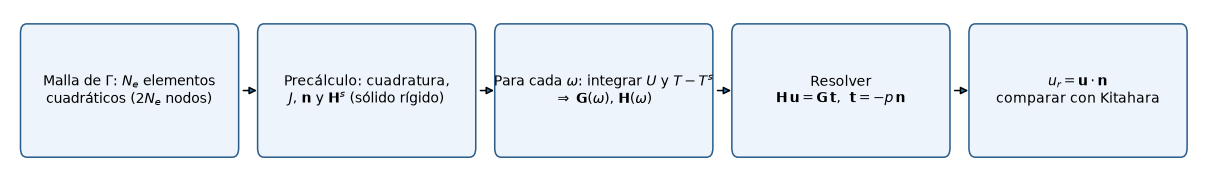

In [11]:
pasos = ["Malla de $\\Gamma$: $N_e$ elementos\ncuadráticos ($2N_e$ nodos)",
         "Precálculo: cuadratura,\n$J$, $\\mathbf{n}$ y $\\mathbf{H}^s$ (sólido rígido)",
         "Para cada $\\omega$: integrar $U$ y $T-T^s$\n$\\Rightarrow$ $\\mathbf{G}(\\omega)$, $\\mathbf{H}(\\omega)$",
         "Resolver\n$\\mathbf{H}\\,\\mathbf{u}=\\mathbf{G}\\,\\mathbf{t}$,  $\\mathbf{t}=-p\\,\\mathbf{n}$",
         "$u_r=\\mathbf{u}\\cdot\\mathbf{n}$\ncomparar con Kitahara"]
fig, ax = plt.subplots(figsize=(14, 1.9))
for k, s in enumerate(pasos):
    x0 = k*3.0
    ax.add_patch(FancyBboxPatch((x0, 0), 2.6, 1, boxstyle="round,pad=0.08", fc="#eef4fb", ec="#2b5d8a"))
    ax.text(x0 + 1.3, 0.5, s, ha="center", va="center", fontsize=9)
    if k < len(pasos) - 1:
        ax.annotate("", xy=(x0 + 2.95, 0.5), xytext=(x0 + 2.7, 0.5), arrowprops=dict(arrowstyle="-|>"))
ax.set_xlim(-0.2, 14.9); ax.set_ylim(-0.2, 1.2); ax.axis("off"); plt.show()

## 5. Reproducción de la Figura 2

Barrido $10 \le \omega \le 150$ rad/s. Como en el artículo: línea = 8 elementos, círculos = 32 elementos, rombos = solución analítica. Se grafica $|u_r|$ promediado sobre los nodos (en $10^{-4}$ m) frente a $\omega/\omega_1$.

In [12]:
w8   = np.linspace(10, 150, 281)
w32  = np.linspace(10, 150, 113)
wan  = np.linspace(10, 150, 23)                    # rombos analíticos
wfin = np.linspace(10, 150, 2001)                  # curva analítica fina (para errores)

ur8  = np.array([np.abs(bem8.resolver(w)).mean() for w in w8])
ur32 = np.array([np.abs(bem32.resolver(w)).mean() for w in w32])
uan  = np.abs(u_r_analitico(wan))
ufin = np.abs(u_r_analitico(wfin))
print("listo:", len(w8), "frecuencias (8 elem.),", len(w32), "frecuencias (32 elem.)")

listo: 281 frecuencias (8 elem.), 113 frecuencias (32 elem.)


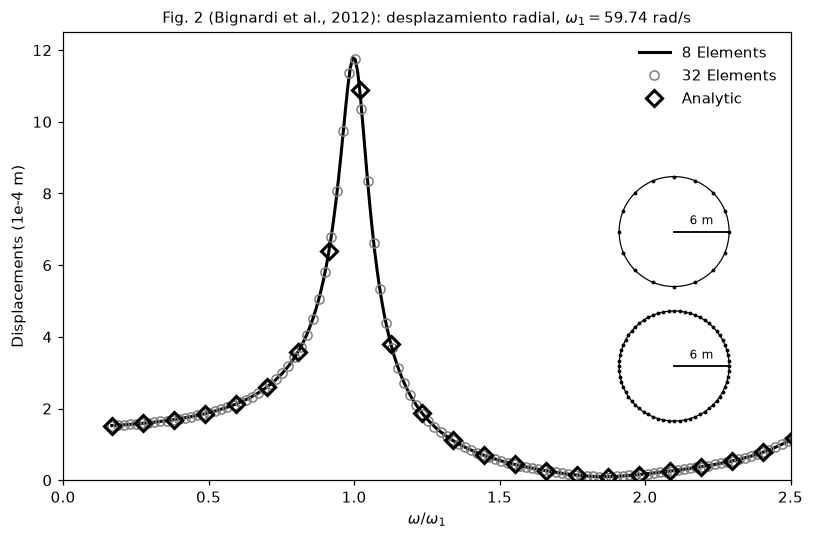

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(w8/OMEGA1, ur8*1e4, "k-", lw=2, label="8 Elements")
ax.plot(w32/OMEGA1, ur32*1e4, "o", mfc="none", mec="gray", ms=6, label="32 Elements")
ax.plot(wan/OMEGA1, uan*1e4, "D", mfc="none", mec="k", mew=2, ms=7, label="Analytic")
ax.set_xlabel(r"$\omega/\omega_1$"); ax.set_ylabel("Displacements (1e-4 m)")
ax.set_xlim(0, 2.5); ax.set_ylim(0, 12.5); ax.legend(loc="upper right", frameon=False)

# insertos con las mallas, como en el artículo
for (ne, y0) in [(8, 0.42), (32, 0.12)]:
    ins = ax.inset_axes([0.72, y0, 0.24, 0.27])
    nodes, conn = malla_circulo(R, ne)
    eta = np.linspace(-1, 1, 20)
    for cn in conn:
        X = shape(eta) @ nodes[cn]; ins.plot(X[:, 0], X[:, 1], "k-", lw=0.8)
    ins.plot(nodes[:, 0], nodes[:, 1], "k.", ms=3)
    ins.plot([0, R], [0, 0], "k-", lw=1.2); ins.text(R/2, 0.8, "6 m", ha="center", fontsize=8)
    ins.set_aspect("equal"); ins.axis("off")
ax.set_title(r"Fig. 2 (Bignardi et al., 2012): desplazamiento radial, $\omega_1=%.2f$ rad/s" % OMEGA1, fontsize=10)
plt.tight_layout(); plt.show()

### 5.1 Error relativo frente a la solución exacta

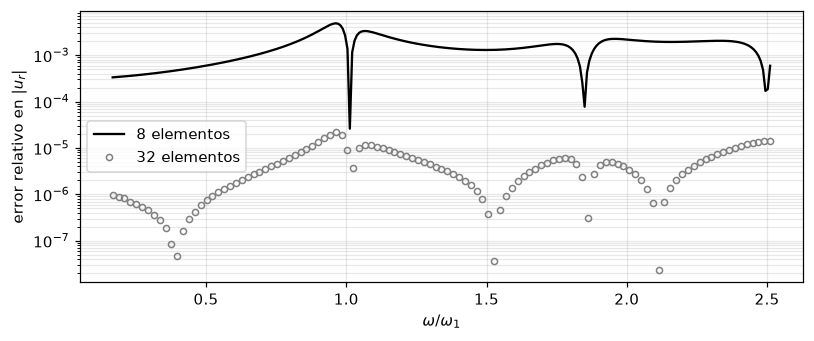

error máximo: 8 elem = 4.87e-03,  32 elem = 2.15e-05


In [14]:
e8  = np.abs(ur8  - np.abs(u_r_analitico(w8)))/np.abs(u_r_analitico(w8))
e32 = np.abs(ur32 - np.abs(u_r_analitico(w32)))/np.abs(u_r_analitico(w32))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.semilogy(w8/OMEGA1, e8, "k-", label="8 elementos")
ax.semilogy(w32/OMEGA1, e32, "o", mfc="none", mec="gray", ms=4, label="32 elementos")
ax.set_xlabel(r"$\omega/\omega_1$"); ax.set_ylabel(r"error relativo en $|u_r|$")
ax.grid(True, which="both", alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()
print(f"error máximo: 8 elem = {e8.max():.2e},  32 elem = {e32.max():.2e}")

### 5.2 Convergencia con el número de elementos

Con elementos cuadráticos sobre una geometría curva se espera convergencia algebraica rápida (del orden de $h^3$–$h^4$ en problemas suaves). Lo comprobamos en una frecuencia baja, en la resonancia y en una alta. Para $N_e\gtrsim32$ el error se estanca en $\sim10^{-6}$: es el piso que impone la cuadratura de 16 puntos (no la discretización); aumentar los puntos de Gauss lo baja.

omega =  30.00: pendientes = [ 3.55  4.    5.67 -0.13]


omega =  59.74: pendientes = [2.18 3.58 3.88 4.33]


omega = 120.00: pendientes = [ 3.62  4.13  5.19 -0.83]


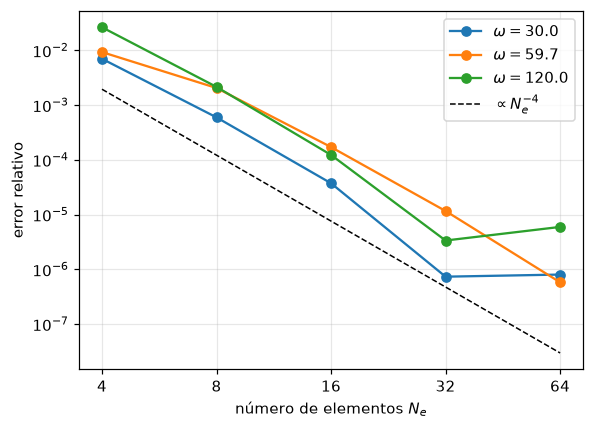

In [15]:
nes = [4, 8, 16, 32, 64]
fig, ax = plt.subplots(figsize=(5.5, 4))
for w in [30.0, OMEGA1, 120.0]:
    ua = abs(u_r_analitico(w))
    err = [abs(np.abs(BEMCilindro(R, ne, mat).resolver(w)).mean() - ua)/ua for ne in nes]
    ax.loglog(nes, err, "o-", label=rf"$\omega={w:.1f}$")
    print(f"omega = {w:6.2f}: pendientes =", np.round(-np.diff(np.log(err))/np.diff(np.log(nes)), 2))
ax.loglog(nes, 0.5*np.array(nes, float)**-4, "k--", lw=1, label=r"$\propto N_e^{-4}$")
ax.set_xticks(nes); ax.set_xticklabels(nes); ax.minorticks_off()
ax.set_xlabel(r"número de elementos $N_e$"); ax.set_ylabel("error relativo")
ax.grid(True, which="both", alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

## 6. Discusión

* **Física.** La curva tiene el aspecto de un oscilador de un grado de libertad: respuesta casi estática $pR/[2(\lambda+\mu)] = 1.5\times10^{-4}$ m para $\omega\ll\omega_1$, un pico en el **modo de respiración** $\omega_1 = 59.74$ rad/s (raíz de $3xJ_0(x)=2J_1(x)$), y un mínimo cerca de $\omega/\omega_1\approx1.8$ (antirresonancia, $J_1(k_pR)\approx0$, donde la superficie apenas se mueve). La altura del pico ($\approx 11.8\times10^{-4}$ m) la controla $\beta$ mediante $\mu^*=\mu(1+2i\beta)$.
* **Numérica.** Incluso **8 elementos cuadráticos** (16 nodos, 32 incógnitas) dan errores por debajo del 1 % en todo el rango; con 32 elementos la diferencia es invisible (~$10^{-5}$). Esto concuerda con la observación del artículo (“*the agreement with theory is remarkable*”).
* **Claves de implementación.** (i) Solución fundamental dinámica con funciones $K_n$ de argumento complejo (incluye el amortiguamiento); (ii) integración logarítmica con partición + mapeo cuadrático; (iii) término libre y valor principal vía movimiento de sólido rígido sobre $T^s$, sumando la parte regular $T-T^s$.
* **Conexión con la inversión.** Este mismo ensamblaje $\mathbf H\mathbf u=\mathbf G\mathbf t$ (por capas y con condiciones de continuidad en las interfaces, ecs. 2–5) es el modelo directo que Bignardi et al. derivan respecto a las coordenadas nodales de las interfaces para su inversión geométrica (ecs. 6–14).
* **Limitación:** cerca de $\omega\to0$ la matriz $\mathbf H$ tiende a ser singular (modos de sólido rígido del problema interior con tracciones impuestas), por eso el rango empieza en $\omega=10$ rad/s, como en el artículo.